In [38]:
# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [39]:
df = pd.read_csv("/content/Advertising.csv")
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [40]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape:
(200, 5)

Column Names:
Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB

Statistical Summary:
       Unnamed: 0          TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000  200.000000
mean   100.500000  147.042500   23.264000   30.554000   14.022500
std     57.879185   85.854236   14.846809   21.778621    5.217457
min      1.000000    0.700000    0.000000    0.300000    1.600000
25%     50.750000   74.375000    9.975000   12.750000   10.375000
50%  

In [41]:
# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Check missing values
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

print("\nCleaned Dataset:")
print(df.head())

print("\nFinal Shape:")
print(df.shape)

print(df.dtypes)

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Cleaned Dataset:
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Final Shape:
(200, 4)
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


In [49]:
# Convert advertising spend and sales into numeric values

for col in ["TV", "Radio", "Newspaper", "Sales"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["TV", "Radio", "Newspaper", "Sales"])

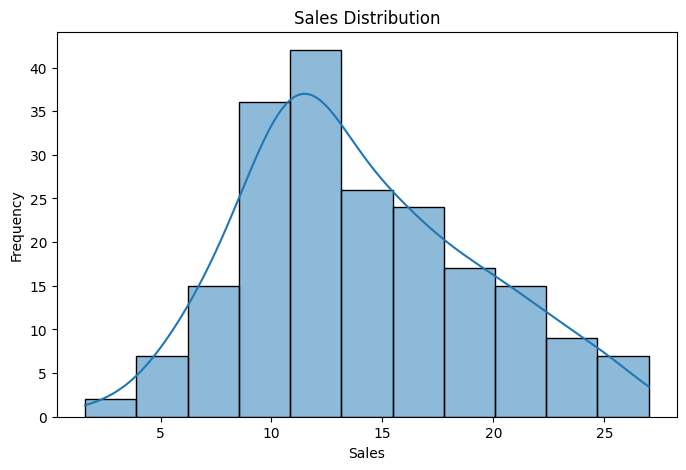

In [50]:
# Step 4: Exploratory Data Analysis

# Sales distribution

plt.figure(figsize=(8, 5))

sns.histplot(df["Sales"], kde=True)

plt.title("Sales Distribution")

plt.xlabel("Sales")

plt.ylabel("Frequency")

plt.show()



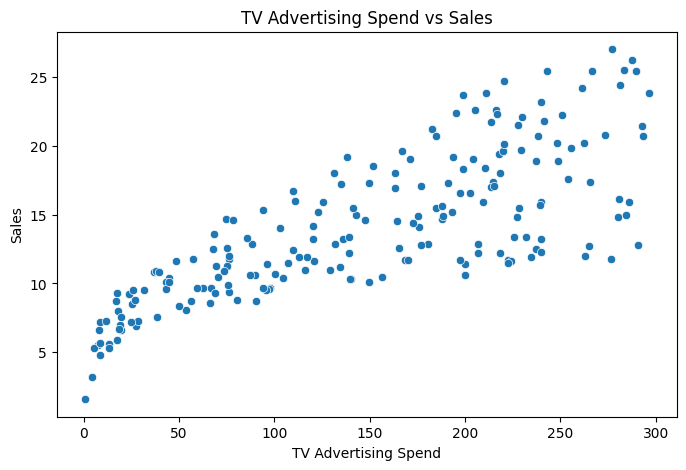

In [52]:
# Advertising Spend vs Sales

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="TV",
    y="Sales"
)

plt.title("TV Advertising Spend vs Sales")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")

plt.show()

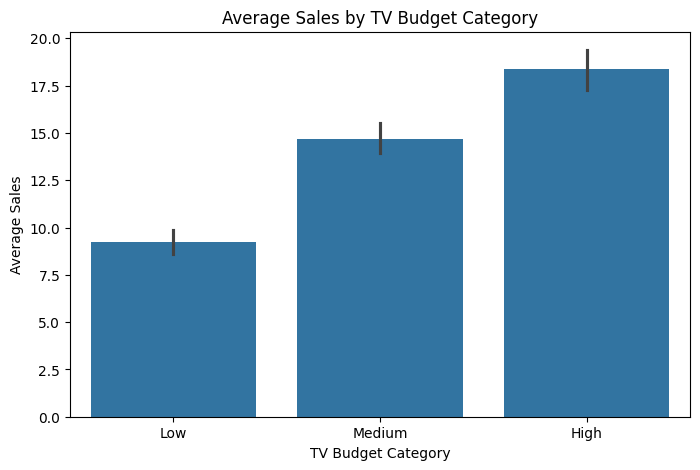

In [54]:
# Compare average sales by dividing TV advertising spend into categories

plt.figure(figsize=(8, 5))

# Create temporary budget categories to visualize average sales
df_temp = df.copy()
df_temp['TV_Budget_Category'] = pd.cut(df_temp['TV'], bins=[0, 100, 200, 300], labels=['Low', 'Medium', 'High'])

sns.barplot(
    data=df_temp,
    x="TV_Budget_Category",
    y="Sales"
)

plt.title("Average Sales by TV Budget Category")
plt.xlabel("TV Budget Category")
plt.ylabel("Average Sales")

plt.show()

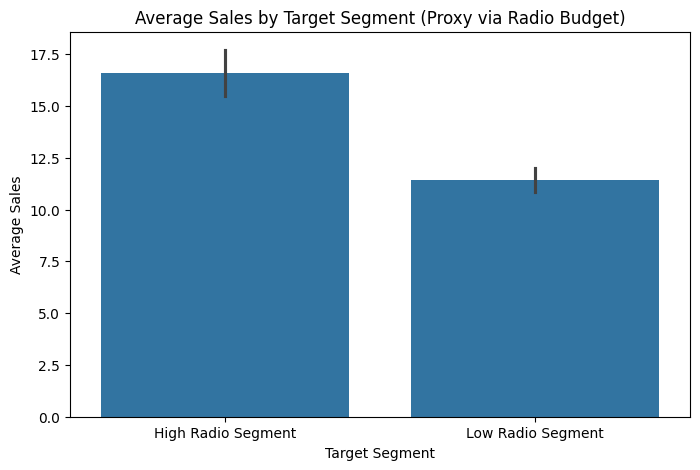

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The dataset does not have a 'Target_Segment' column.
# Let's create a temporary proxy segment based on Radio spend to illustrate the concept.

df_temp = df.copy()
radio_median = df_temp['Radio'].median()
df_temp['Target_Segment'] = df_temp['Radio'].apply(
    lambda x: 'High Radio Segment' if x >= radio_median else 'Low Radio Segment'
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_temp,
    x="Target_Segment",
    y="Sales"
)

plt.title("Average Sales by Target Segment (Proxy via Radio Budget)")
plt.ylabel("Average Sales")
plt.xlabel("Target Segment")

plt.show()

In [59]:
# Step 5: Define input and output

# The dataset contains 'TV', 'Radio', and 'Newspaper' as feature columns
X = df[
    ["TV", "Radio", "Newspaper"]
]

y = df["Sales"]

In [60]:
# Step 6: Select numerical and categorical features

numeric_features = ["Advertising_Spend"]

categorical_features = [
    "Target_Segment",
    "Platform"
]


In [61]:
# Step 7: Preprocessing

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


In [62]:
# Step 8: Create machine learning model

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)


In [63]:
# Step 9: Create complete pipeline

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)


In [64]:
# Step 10: Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


In [66]:
# Step 11: Reconfigure preprocessor with actual columns and train model

# Redefine numerical features with the actual columns present in X
numeric_features = ["TV", "Radio", "Newspaper"]

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Recreate preprocessor with correct numerical features and no categorical ones
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ]
)

# Reconstruct the pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

# Train model
pipeline.fit(X_train, y_train)

# Step 12: Make predictions
y_pred = pipeline.predict(X_test)

# Step 13: Model evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


MODEL PERFORMANCE
MAE: 0.6296250000000021
RMSE: 0.7575226399257009
R2 Score: 0.9818195432831535



Prediction Results:
    Actual Sales  Predicted Sales
0           16.9          17.7615
1           22.4          21.6665
2           21.4          20.6595
3            7.3           6.7395
4           24.7          23.0960
5           12.6          13.5155
6           22.3          22.4860
7            8.4           9.6625
8           11.5          11.8545
9           14.9          15.5040
10           9.5           7.4855
11           8.7           9.0335
12          11.9          12.1285
13           5.3           4.8615
14          10.3          10.5570
15          11.7          12.6515
16           5.5           6.5045
17          16.6          16.4230
18          11.3          11.3625
19          18.9          19.6895
20          19.7          19.9810
21          12.5          12.9895
22          10.9          10.2715
23          22.2          22.0090
24           9.3           9.9565
25           8.1           8.9615
26          21.7          22.2195
27          13.4          1

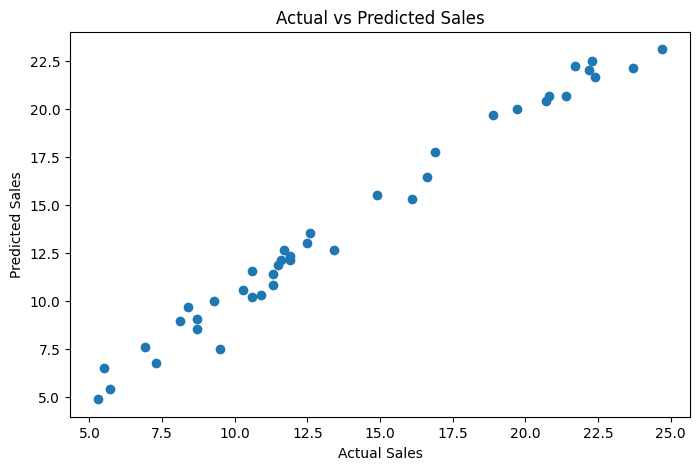

In [67]:
# Step 14: Actual vs Predicted Sales

results = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

print("\nPrediction Results:")

print(results)


plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")

plt.ylabel("Predicted Sales")

plt.title("Actual vs Predicted Sales")

plt.show()


Feature Importance:
          Feature  Importance
0         num__TV    0.624727
1      num__Radio    0.362119
2  num__Newspaper    0.013153


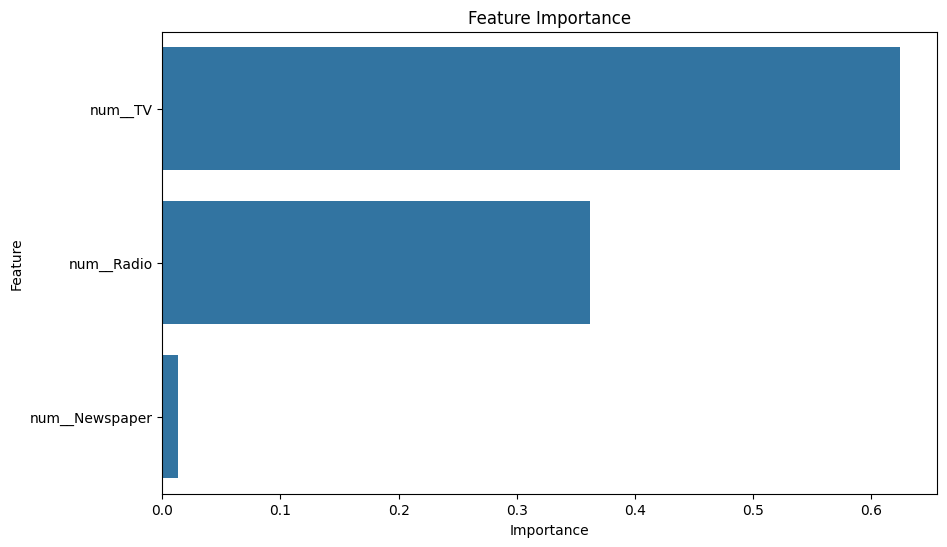

In [68]:
# Step 15: Feature importance

feature_names = pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = pipeline.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")

print(importance_df)


plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

In [72]:

# Step 16: Save trained model

import joblib
import sklearn

print("Scikit-learn version:", sklearn.__version__)

# Save the newly trained pipeline
joblib.dump(pipeline, "sales_model.pkl")

# Save feature names if available
joblib.dump(X.columns.tolist(), "sales_feature_names.pkl")

print("\nModel saved successfully!")
print("File created: sales_model.pkl")
print("Feature names saved successfully!")


Scikit-learn version: 1.6.1

Model saved successfully!
File created: sales_model.pkl
Feature names saved successfully!


In [71]:
%%writefile app.py
# ==========================================
# SALES PREDICTION STREAMLIT APPLICATION
# ==========================================

import streamlit as st
import pandas as pd
import joblib
from pathlib import Path

# Load saved model
HERE = Path(__file__).resolve().parent
model = joblib.load(HERE / "sales_model.pkl")

# Page configuration
st.set_page_config(
    page_title="Sales Prediction",
    page_icon="📊",
    layout="centered"
)

# Application heading
st.title("📊 Sales Prediction Using Python")
st.write(
    "Predict sales based on advertising budgets spent on TV, Radio, and Newspaper."
)
st.divider()

# User input
st.subheader("Enter Campaign Budgets")

with st.form("sales_form"):
    tv_budget = st.number_input(
        "TV Advertising Budget ($)",
        min_value=0.0,
        value=150.0,
        step=10.0
    )

    radio_budget = st.number_input(
        "Radio Advertising Budget ($)",
        min_value=0.0,
        value=25.0,
        step=5.0
    )

    newspaper_budget = st.number_input(
        "Newspaper Advertising Budget ($)",
        min_value=0.0,
        value=30.0,
        step=5.0
    )

    submitted = st.form_submit_button(
        "Predict Sales"
    )

# Prediction
if submitted:
    # Features must match the exact names used during training: TV, Radio, Newspaper
    input_data = pd.DataFrame({
        "TV": [tv_budget],
        "Radio": [radio_budget],
        "Newspaper": [newspaper_budget]
    })

    prediction = model.predict(input_data)[0]

    st.success(
        f"Predicted Sales: {prediction:,.2f} units"
    )

    st.info(
        "This prediction is an estimate based on "
        "the historical data used to train the model."
    )

# Advertising impact analysis
st.divider()
st.subheader("Scenario Simulation")
st.write(
    "Compare predicted sales with alternative TV advertising budgets while keeping Radio and Newspaper constant."
)

if submitted:
    budgets = [
        tv_budget * 0.5,
        tv_budget,
        tv_budget * 1.5,
        tv_budget * 2.0
    ]

    scenario_data = pd.DataFrame({
        "TV": budgets,
        "Radio": [radio_budget] * len(budgets),
        "Newspaper": [newspaper_budget] * len(budgets)
    })

    scenario_predictions = model.predict(scenario_data)

    comparison = pd.DataFrame({
        "TV Budget": budgets,
        "Predicted Sales": scenario_predictions
    })

    st.dataframe(
        comparison,
        use_container_width=True
    )

    st.line_chart(
        comparison.set_index("TV Budget")
    )

st.divider()
st.caption(
    "Sales Prediction Project | Python | Scikit-learn | Streamlit"
)

Writing app.py
